<a href="https://colab.research.google.com/github/vanesamrd/ML_ganjil/blob/main/Vanesa_JS9_T01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Membaca dataset
df = pd.read_csv('/content/voice.csv')

# Menampilkan informasi dasar dan 5 baris pertama
print("Info Dataset:")
df.info()
display(df.head())

# Memeriksa distribusi kelas target
print("\nDistribusi Target (label):")
print(df['label'].value_counts())

Info Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float64
 19  modindx   3168 non-null   float64
 20  label     3168 n

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male



Distribusi Target (label):
label
male      1584
female    1584
Name: count, dtype: int64


Korelasi Fitur dengan Label Target:
meanfun    -0.833921
Q25        -0.511455
centroid   -0.337415
meanfreq   -0.337415
median     -0.283919
maxdom     -0.195657
mindom     -0.194974
dfrange    -0.192213
meandom    -0.191067
mode       -0.171775
maxfun     -0.166461
minfun     -0.136692
modindx     0.030801
skew        0.036627
Q75         0.066906
kurt        0.087195
sfm         0.357499
sd          0.479539
sp.ent      0.490552
IQR         0.618916
label       1.000000
Name: label, dtype: float64


/tmp/ipykernel_3305/4266256887.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances.values, y=importances.index, palette='viridis')


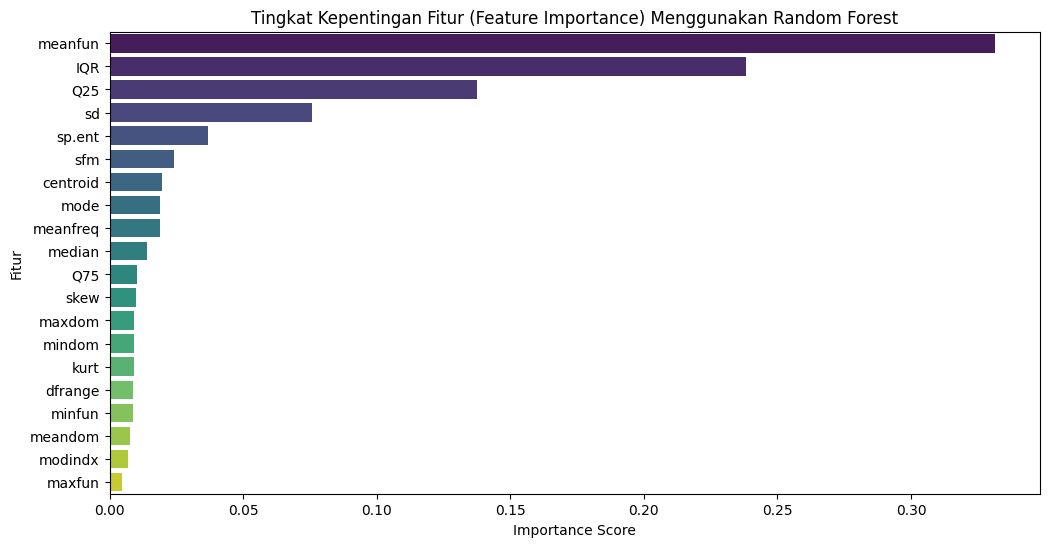

Fitur teratas berdasarkan tingkat kepentingan:
meanfun     0.331494
IQR         0.238313
Q25         0.137508
sd          0.075662
sp.ent      0.036819
sfm         0.024089
centroid    0.019465
mode        0.019009
meanfreq    0.018905
median      0.014050
dtype: float64


In [3]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier

# 1. Encode label ke numerik (female = 0, male = 1)
le = LabelEncoder()
df_encoded = df.copy()
df_encoded['label'] = le.fit_transform(df['label'])

# 2. Hitung korelasi dengan target
correlations = df_encoded.corr()['label'].sort_values()
print("Korelasi Fitur dengan Label Target:")
print(correlations)

# 3. Hitung Feature Importance dengan Random Forest
X = df_encoded.drop('label', axis=1)
y = df_encoded['label']

# Standardisasi fitur terlebih dahulu
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

rf = RandomForestClassifier(random_state=42)
rf.fit(X_scaled, y)

importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

# Plot Feature Importance
plt.figure(figsize=(12, 6))
sns.barplot(x=importances.values, y=importances.index, palette='viridis')
plt.title('Tingkat Kepentingan Fitur (Feature Importance) Menggunakan Random Forest')
plt.xlabel('Importance Score')
plt.ylabel('Fitur')
plt.show()

print("Fitur teratas berdasarkan tingkat kepentingan:")
print(importances.head(10))

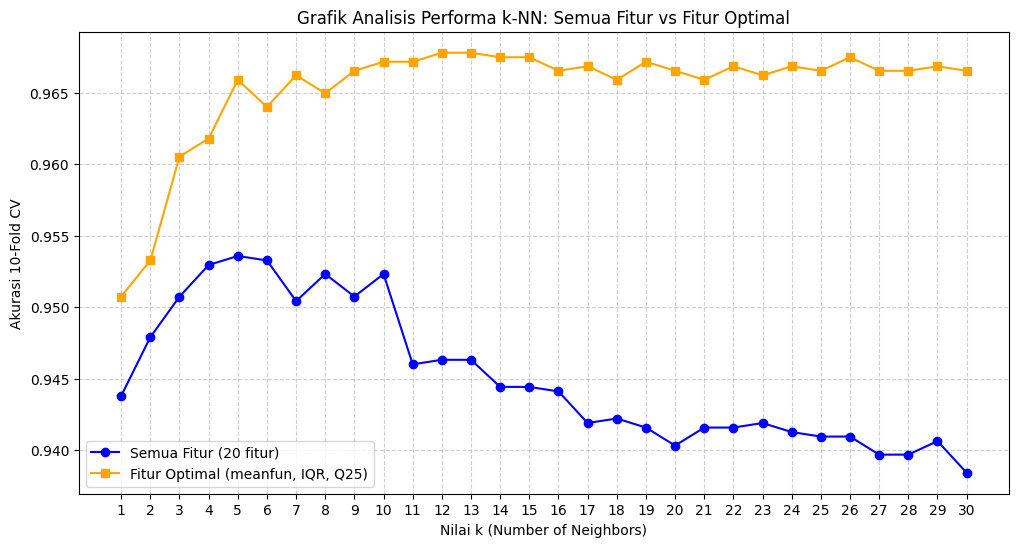

Skenario Semua Fitur: Akurasi Terbaik = 0.9536 pada k = 5
Skenario Fitur Optimal: Akurasi Terbaik = 0.9678 pada k = 13


In [4]:
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier

# Mempersiapkan data
k_range = range(1, 31)

# Skenario A: Semua fitur
X_all = X_scaled
y_all = y

# Skenario B: Fitur Optimal Utama ('meanfun', 'IQR', 'Q25')
optimal_features = ['meanfun', 'IQR', 'Q25']
X_opt = X_scaled[optimal_features]

# List untuk menyimpan skor rata-rata akurasi
scores_all = []
scores_opt = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)

    # Evaluasi dengan 10-Fold CV untuk Skenario A
    score_a = cross_val_score(knn, X_all, y_all, cv=10, scoring='accuracy').mean()
    scores_all.append(score_a)

    # Evaluasi dengan 10-Fold CV untuk Skenario B
    score_b = cross_val_score(knn, X_opt, y_all, cv=10, scoring='accuracy').mean()
    scores_opt.append(score_b)

# Menampilkan Visualisasi Perbandingan
plt.figure(figsize=(12, 6))
plt.plot(k_range, scores_all, marker='o', label='Semua Fitur (20 fitur)', color='blue')
plt.plot(k_range, scores_opt, marker='s', label='Fitur Optimal (meanfun, IQR, Q25)', color='orange')
plt.xlabel('Nilai k (Number of Neighbors)')
plt.ylabel('Akurasi 10-Fold CV')
plt.title('Grafik Analisis Performa k-NN: Semua Fitur vs Fitur Optimal')
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

# Mencari k terbaik dari masing-masing skenario
best_k_all = k_range[np.argmax(scores_all)]
best_score_all = max(scores_all)

best_k_opt = k_range[np.argmax(scores_opt)]
best_score_opt = max(scores_opt)

print(f"Skenario Semua Fitur: Akurasi Terbaik = {best_score_all:.4f} pada k = {best_k_all}")
print(f"Skenario Fitur Optimal: Akurasi Terbaik = {best_score_opt:.4f} pada k = {best_k_opt}")